# Ice Cream Sales Model
Predict daily ice cream sales. Original predictor: **temperature**. New predictors I added: **weekend** (more people out) and **rainfall** (rain keeps people home).

The data is simulated because no real dataset was provided.

In [1]:
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

## 1. Simulate the data

In [2]:
rng = np.random.default_rng(42)
n = 400
temp = rng.uniform(5, 38, n)
weekend = rng.integers(0, 2, n)
rain = np.where(rng.random(n) < 0.3, rng.uniform(1, 25, n), 0.0)
sales = 20 + 6.5*temp + 45*weekend - 2.2*rain + rng.normal(0, 15, n)

df = pd.DataFrame({"temperature_c": temp.round(1), "is_weekend": weekend,
                   "rainfall_mm": rain.round(1), "sales": sales.clip(min=0).round(0)})
df.to_csv("ice_cream_data.csv", index=False)
df.head()

,temperature_c,is_weekend,rainfall_mm,sales
0,30.5,0,0.0,213.0
1,19.5,0,0.0,160.0
2,33.3,1,0.0,256.0
3,28.0,1,0.0,260.0
4,8.1,1,0.0,112.0


## 2. Explore

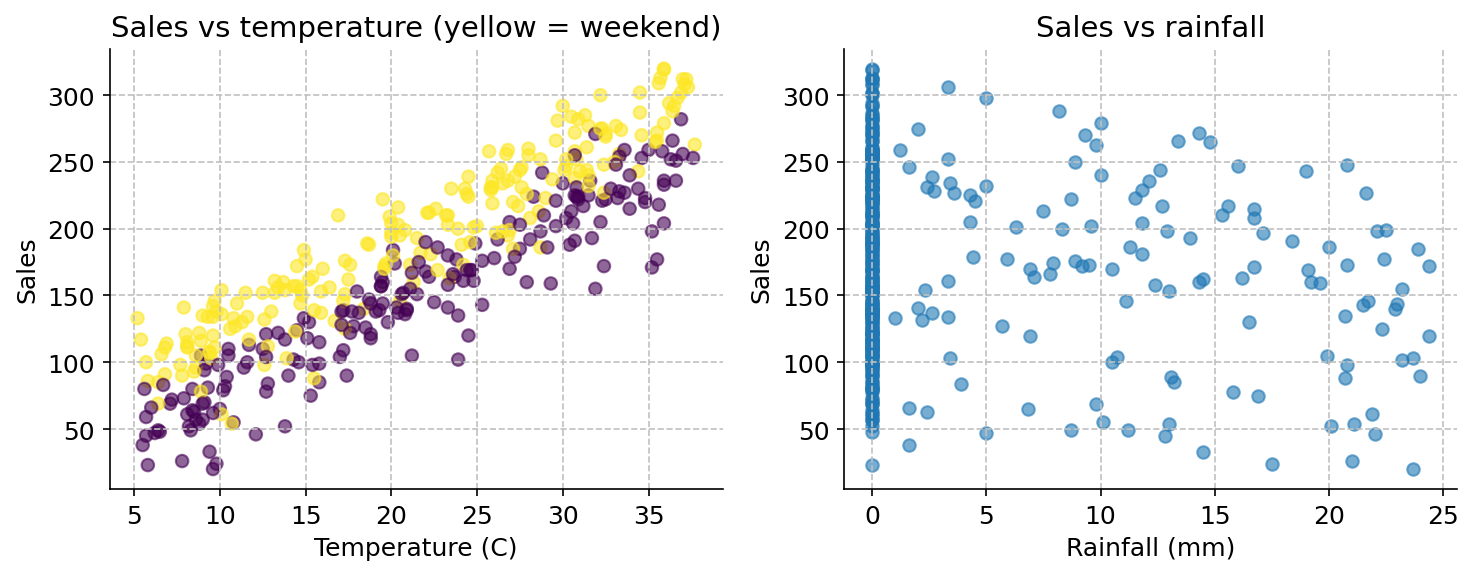

,temperature_c,is_weekend,rainfall_mm,sales
temperature_c,1.00,0.01,0.08,0.89
is_weekend,0.01,1.00,0.02,0.33
rainfall_mm,0.08,0.02,1.00,-0.15
sales,0.89,0.33,-0.15,1.00


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(df.temperature_c, df.sales, c=df.is_weekend, alpha=.6)
ax[0].set(xlabel="Temperature (C)", ylabel="Sales", title="Sales vs temperature (yellow = weekend)")
ax[1].scatter(df.rainfall_mm, df.sales, alpha=.6)
ax[1].set(xlabel="Rainfall (mm)", ylabel="Sales", title="Sales vs rainfall")
plt.tight_layout(); plt.show()
df.corr().round(2)

## 3. Train the model with the new predictors

In [4]:
FEATURES = ["temperature_c", "is_weekend", "rainfall_mm"]
X_train, X_test, y_train, y_test = train_test_split(df[FEATURES], df["sales"], test_size=0.2, random_state=1)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print("R2:", round(r2_score(y_test, pred), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 1), "ice creams")
dict(zip(FEATURES, model.coef_.round(2)))

R2: 0.967
MAE: 10.6 ice creams


{'temperature_c': np.float64(6.61),
 'is_weekend': np.float64(43.99),
 'rainfall_mm': np.float64(-2.29)}

## 4. Save the model

In [5]:
joblib.dump(model, "ice_cream_model.joblib")
loaded = joblib.load("ice_cream_model.joblib")
test = pd.DataFrame([[30, 1, 0]], columns=FEATURES)
print("Hot dry weekend prediction:", round(loaded.predict(test)[0]))

Hot dry weekend prediction: 260
